In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

Graphs show the whole distribution. **Summary measures** condense it into a few
numbers that describe its centre, its spread and its shape. This part introduces the
empirical distribution function, which contains all the information of the data, and
the measures of centre and position; the [next part](03-dispersion-shape.ipynb)
covers dispersion and shape. We continue with the Madrid listings.

In [2]:
listings = pl.read_csv("data/processed/idealista/madrid_listings_2018.csv").select(
    "listing_id", "district", "zone", "condition",
    "price", "price_m2", "area_m2", "bedrooms", "bathrooms",
    "floor", "lift", "terrace", "construction_year", "dist_centre_km",
)

**Notation.** For data $x_1, \dots, x_n$ we write $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$
for the same values sorted in increasing order, the **order statistics**. Thus
$x_{(1)}$ is the minimum and $x_{(n)}$ the maximum.

## The empirical distribution function

::: {#def-ecdf}
## Empirical distribution function
The **empirical distribution function** of $x_1, \dots, x_n$ is the function
$F_n : \mathbb{R} \to [0, 1]$,
$$
F_n(x) = \frac{1}{n}\,\#\{i : x_i \le x\},
$$
the proportion of observations less than or equal to $x$.
:::

It extends the cumulative frequencies $F_i$ of
[part 1](01-freq-graphs.ipynb#ordinal-variables-cumulative-frequencies) to every real
number $x$, and does not require grouping the data.

::: {#prp-ecdf}
## Properties of the empirical distribution function

1. $F_n$ is non-decreasing, $F_n(x) = 0$ for $x < x_{(1)}$ and $F_n(x) = 1$ for
   $x \ge x_{(n)}$.
2. $F_n$ is a step function: it is constant between consecutive distinct values, and at
   each observed value $v$ it jumps by the relative frequency of $v$.
3. For $a < b$, the proportion of observations in $(a, b]$ is $F_n(b) - F_n(a)$.
:::

::: {.proof}
If $x \le y$, every observation with $x_i \le x$ also satisfies $x_i \le y$, so the
count defining $F_n(x)$ cannot exceed that of $F_n(y)$. No observation is below
$x_{(1)}$ and all are at most $x_{(n)}$, which gives the values 0 and 1. The set
$\{i : x_i \le x\}$ only changes when $x$ reaches an observed value $v$, and then it
gains the observations equal to $v$, which proves 2. Finally,
$\{i : x_i \le b\}$ is the disjoint union of $\{i : x_i \le a\}$ and
$\{i : a < x_i \le b\}$, so the counts add up, which proves 3.
:::

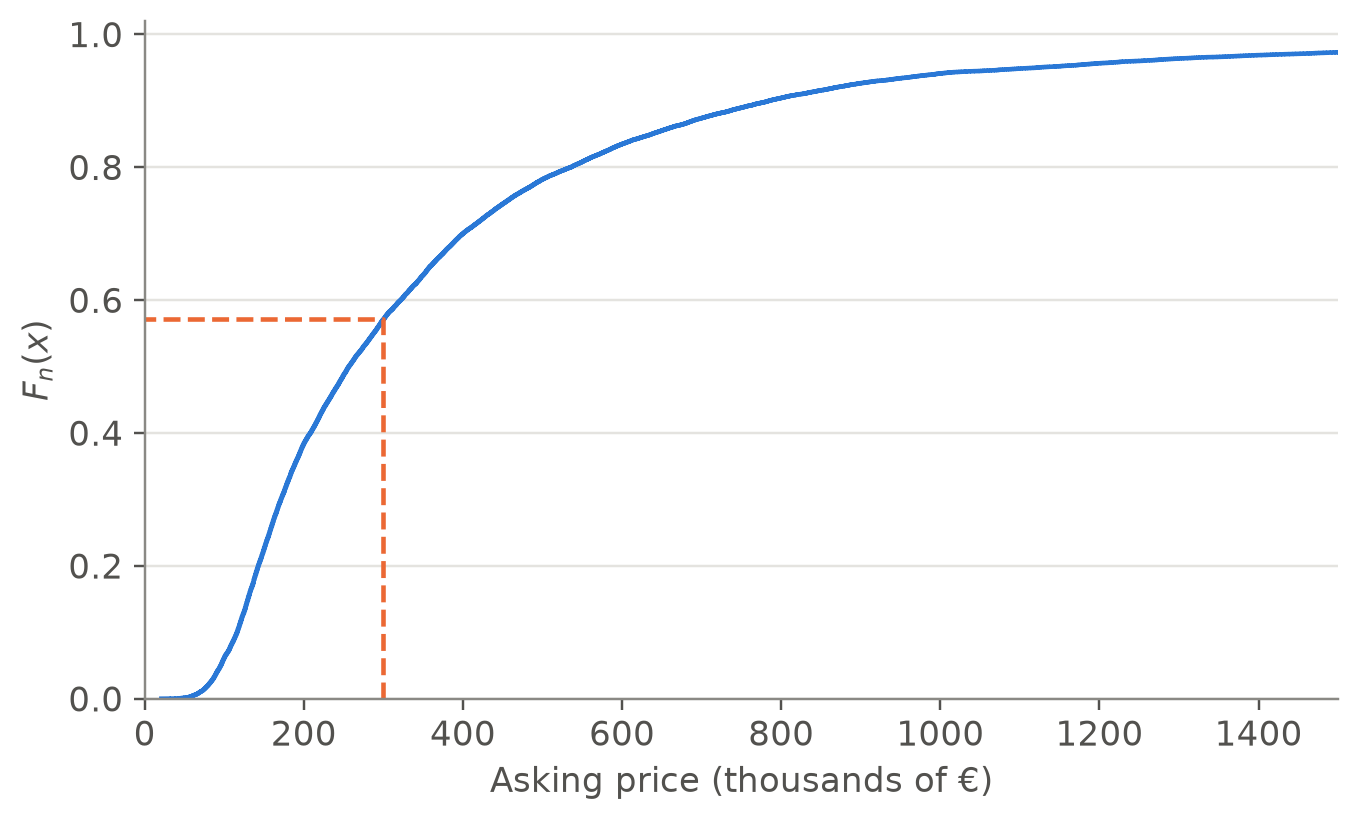

F_n(300,000) = 0.571


In [3]:
#| label: fig-ecdf
#| fig-cap: "Empirical distribution function of the asking price (axis cut at 1.5 million €). The dashed lines read off F_n(300,000)."
price_sorted = np.sort(listings["price"].to_numpy())
n = len(price_sorted)
F300 = np.mean(price_sorted <= 300_000)

fig, ax = plt.subplots()
ax.step(price_sorted / 1000, np.arange(1, n + 1) / n, where="post", color=COLORS["blue"])
ax.plot([300, 300, 0], [0, F300, F300], ls="--", color=COLORS["orange"])
ax.set_xlim(0, 1_500)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Asking price (thousands of €)")
ax.set_ylabel("$F_n(x)$")
plt.show()
print(f"F_n(300,000) = {F300:.3f}")

About 57 % of the listings ask for 300,000 € or less. The empirical distribution
function answers any question of this kind without grouping, and it is the basis of
the quantiles defined below. With 75,735 observations the steps are too small to see,
and $F_n$ looks like a continuous curve: steep where the data are concentrated, flat in
the tail.

## Measures of centre

::: {#def-centre}
## Mean, median and mode

- The **mean** is $\displaystyle \bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$.
- The **median** is the central value of the ordered data:
  $Me = x_{((n+1)/2)}$ if $n$ is odd, and $Me = \frac12\big(x_{(n/2)} + x_{(n/2+1)}\big)$
  if $n$ is even.
- The **mode** is the most frequent value (or category).
:::

In [4]:
listings.select(
    mean=pl.col("price").mean(),
    median=pl.col("price").median(),
)

mean,median
"388,892.1","257,000.0"


The mean (about 389,000 €) is much larger than the median (257,000 €): a few very
expensive dwellings pull the mean upwards but hardly affect the median. Half of the
listings ask for less than 257,000 €, and the mean is above what most of them ask.

### Properties of the mean and the median

::: {#prp-mean}
## Least-squares property of the mean
For any data $x_1, \dots, x_n$:

1. $\sum_{i=1}^n (x_i - \bar x) = 0$: the deviations from the mean cancel out.
2. For every $c \in \mathbb{R}$,
   $\displaystyle \sum_{i=1}^n (x_i - c)^2 = \sum_{i=1}^n (x_i - \bar x)^2 + n(\bar x - c)^2 .$

Hence the mean is the unique value $c$ that minimises $\sum_i (x_i - c)^2$.
:::

::: {.proof}
1. $\sum_i (x_i - \bar x) = \sum_i x_i - n\bar x = n\bar x - n\bar x = 0$.

2. Add and subtract $\bar x$: $x_i - c = (x_i - \bar x) + (\bar x - c)$. Squaring and
   adding,
   $$
   \sum_i (x_i - c)^2 = \sum_i (x_i - \bar x)^2 + 2(\bar x - c)\sum_i (x_i - \bar x) + n(\bar x - c)^2,
   $$
   and the middle term is zero by 1. The last term is non-negative and vanishes only
   for $c = \bar x$.
:::

The "add and subtract, expand, the cross term vanishes" argument of this proof is the
most frequent proof in statistics: it reappears in the decomposition of the variance
into groups ([part 3](03-dispersion-shape.ipynb)), in regression and in analysis of
variance.

::: {#prp-median}
## The median minimises the sum of absolute deviations
For any data, a median $Me$ satisfies $\sum_i |x_i - Me| \le \sum_i |x_i - c|$ for
every $c \in \mathbb{R}$.
:::

::: {.proof}
The function $g(c) = \sum_i |x_i - c|$ is continuous and piecewise linear. On an
interval that contains no observation, moving $c$ to the right by $\delta > 0$ increases
by $\delta$ the distance to each observation on its left and decreases by $\delta$ the
distance to each one on its right, so the slope of $g$ is
$$
\#\{i : x_i < c\} - \#\{i : x_i > c\}.
$$
For $c$ below the median at least half of the observations are above $c$, so the slope is
$\le 0$; for $c$ above the median it is $\ge 0$. Hence $g$ decreases up to the median and
increases after it, and attains its minimum there.
:::

The two propositions say what each measure is best at: the mean is the best single
value when errors are penalised by their **square**, and the median when they are
penalised by their **absolute value**. Squares penalise large errors heavily, which is
why the mean follows the extreme observations.

::: {.callout-caution}
## Robustness: mean versus median

What happens if we add **a single listing**, a palace for sale at 100 million €?

In [5]:
price_with_palace = pl.concat([listings["price"], pl.Series([100_000_000.0])])

pl.DataFrame({
    "measure": ["mean", "median"],
    "original": [listings["price"].mean(), listings["price"].median()],
    "with the palace": [price_with_palace.mean(), price_with_palace.median()],
})

measure,original,with the palace
mean,"388,892.1","390,207.4"
median,"257,000.0","257,000.0"


Even among more than 75,000 listings, one observation raises the mean by about
1,300 €, while the median does not move. In general, changing a single observation by
an amount $\Delta$ changes the mean by $\Delta / n$, with no limit, while the median
can only move to a neighbouring order statistic. This is why housing and income
statistics often report the **median** rather than the mean.
:::

### Weighted means and means of groups

::: {#def-weighted-mean}
## Weighted mean
Given weights $w_1, \dots, w_n \ge 0$ with $\sum_i w_i > 0$, the **weighted mean** is
$\displaystyle \bar x_w = \frac{\sum_{i=1}^n w_i x_i}{\sum_{i=1}^n w_i}$.
:::

::: {#prp-group-means}
## Mean of a union of groups
If the $n$ observations are divided into $G$ groups with sizes $n_1, \dots, n_G$ and
means $\bar x_1, \dots, \bar x_G$, then
$\displaystyle \bar x = \sum_{g=1}^G \frac{n_g}{n}\,\bar x_g$: the overall mean is the mean
of the group means **weighted by the group sizes**.
:::

::: {.proof}
The sum of the observations of group $g$ is $n_g \bar x_g$, so
$\bar x = \frac1n\sum_g n_g \bar x_g$.
:::

In [6]:
by_zone = listings.group_by("zone").agg(n_g=pl.len(), mean_g=pl.col("price").mean())
by_district = listings.group_by("district").agg(mean_g=pl.col("price").mean())

print(f"Overall mean                    : {listings['price'].mean():,.0f} €")
print(f"Weighted mean of the zone means : "
      f"{(by_zone['n_g'] * by_zone['mean_g']).sum() / by_zone['n_g'].sum():,.0f} €")
print(f"Simple mean of the 21 district means: {by_district['mean_g'].mean():,.0f} €")

Overall mean                    : 388,892 €
Weighted mean of the zone means : 388,892 €
Simple mean of the 21 district means: 349,573 €


The simple mean of the district means gives each district the same weight, whatever
its number of listings, and does not equal the overall mean.

::: {.callout-tip}
## Example: what is "the" price per m² of a market?

The mean of `price_m2` gives the same weight to a studio and to a mansion. A housing
market is often summarised instead by the **total value over the total area**,
$\sum_i p_i / \sum_i a_i$. Writing $r_i = p_i / a_i$ for the price per m² of dwelling $i$,
$$
\frac{\sum_i p_i}{\sum_i a_i} = \sum_i \frac{a_i}{\sum_j a_j}\, r_i ,
$$
a mean of the prices per m² **weighted by the areas**:

In [7]:
listings.select(
    simple_mean=pl.col("price_m2").mean(),
    area_weighted=pl.col("price").sum() / pl.col("area_m2").sum(),
)

simple_mean,area_weighted
"3,636.3","3,880.4"


The two answers differ because large dwellings, concentrated in the expensive
districts, ask more per m². Neither is wrong: they answer different questions (the
typical listing or the market as a whole), and a report must say which one it uses.
:::

### Grouped data

When only a frequency table with classes is available, as in many official
publications, the individual values are unknown. The usual approximation assumes that
all the observations of a class are at its **class mark** $x_i$, which gives
$\bar x \approx \sum_i f_i x_i$. For the distance to the centre, grouped in classes of
1 km:

In [8]:
dist_table = (
    listings
    .with_columns(lower=pl.col("dist_centre_km").floor())
    .group_by("lower").agg(n_i=pl.len()).sort("lower")
    .with_columns(mark=pl.col("lower") + 0.5, f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(F_i=pl.col("f_i").cum_sum())
)
print(f"Mean from the classes: {(dist_table['f_i'] * dist_table['mark']).sum():.3f} km")
print(f"Exact mean           : {listings['dist_centre_km'].mean():.3f} km")

Mean from the classes: 4.475 km
Exact mean           : 4.475 km


The error is small because the classes are narrow. A table with an open last class
("1 million € or more") has no class mark for that class, and the grouped mean cannot be
computed without an assumption about it. For grouped data the **modal class** is the
one with the greatest **density** $f_i / a_i$, which coincides with the most frequent class
only when all the widths are equal.

## Measures of position: quantiles

::: {#def-quantile}
## Quantile
The **quantile** of order $p \in (0, 1)$ is
$$
Q_p = \min\{x : F_n(x) \ge p\},
$$
the smallest observed value that leaves at least a proportion $p$ of the data at or
below it. Special cases are the **quartiles** $Q_{0.25}$, $Q_{0.5}$ and $Q_{0.75}$, and the
**percentiles** $P_k = Q_{k/100}$.
:::

For even $n$, this definition gives $Q_{0.5} = x_{(n/2)}$, while @def-centre averages
the two central values: any value between them leaves half of the data on each side,
and both conventions are used. With finite data the definition also produces jumps, and software often smooths it by
**linear interpolation** between order statistics: with $h = 1 + (n-1)p$,
$$
Q_p = x_{(\lfloor h \rfloor)} + \big(h - \lfloor h \rfloor\big)\big(x_{(\lfloor h \rfloor + 1)} - x_{(\lfloor h \rfloor)}\big).
$$
This is the default of NumPy, R and Excel; @hyndman1996 compare nine such conventions.
Polars uses `interpolation="nearest"` unless told otherwise. With large data the
differences are negligible:

In [9]:
listings.select(
    [pl.col("price").quantile(p, interpolation="linear").alias(f"Q_{p}")
     for p in [0.10, 0.25, 0.50, 0.75, 0.90]]
)

Q_0.1,Q_0.25,Q_0.5,Q_0.75,Q_0.9
"116,000.0","157,000.0","257,000.0","456,000.0","785,000.0"


A quarter of the listings ask for less than 157,000 €, and a quarter for more than
456,000 €; only one in ten asks for more than 785,000 €.

::: {#prp-equivariance}
## Quantiles and monotone transformations
If $g$ is strictly increasing and $y_i = g(x_i)$, then $Q_p(y) = g\big(Q_p(x)\big)$ for every $p$.
The mean has this property only for linear transformations $g(x) = a + bx$.
:::

::: {.proof}
A strictly increasing $g$ preserves the order, so $x_i \le x$ if and only if
$g(x_i) \le g(x)$, and $F_n^{y}(g(x)) = F_n^{x}(x)$. The smallest observed $x$ with
$F_n^{x}(x) \ge p$ is therefore mapped to the smallest observed $y$ with $F_n^{y}(y) \ge p$.
For the mean, $\frac1n\sum(a + bx_i) = a + b\bar x$; the counterexample below shows that
it fails for the logarithm.
:::

In [10]:
log_price = listings["price"].log()
print(f"median of log(price) = {log_price.median():.4f}   "
      f"log(median price) = {np.log(listings['price'].median()):.4f}")
print(f"mean of log(price)   = {log_price.mean():.4f}   "
      f"log(mean price)   = {np.log(listings['price'].mean()):.4f}")

median of log(price) = 12.4568   log(median price) = 12.4568
mean of log(price)   = 12.5436   log(mean price)   = 12.8711


This is why the median and the quantiles are the natural summaries of **ordinal**
variables (Stevens' scales of [Topic 1](../01-introduction/02-types-of-variables.ipynb#measurement-scales)):
they do not change their meaning under any relabelling that preserves the order.

### Quantiles of grouped data

If only classes are known, we assume that the observations are spread **uniformly**
within each class. The cumulative frequency is then a polygon, the **ogive**, joining
the points $(L_i, F_i)$, and the quantile is read off it by linear interpolation: if
class $i$, $[L_{i-1}, L_i)$, is the first with $F_i \ge p$,
$$
Q_p \approx L_{i-1} + \frac{p - F_{i-1}}{f_i}\, a_i .
$$ {#eq-grouped-quantile}

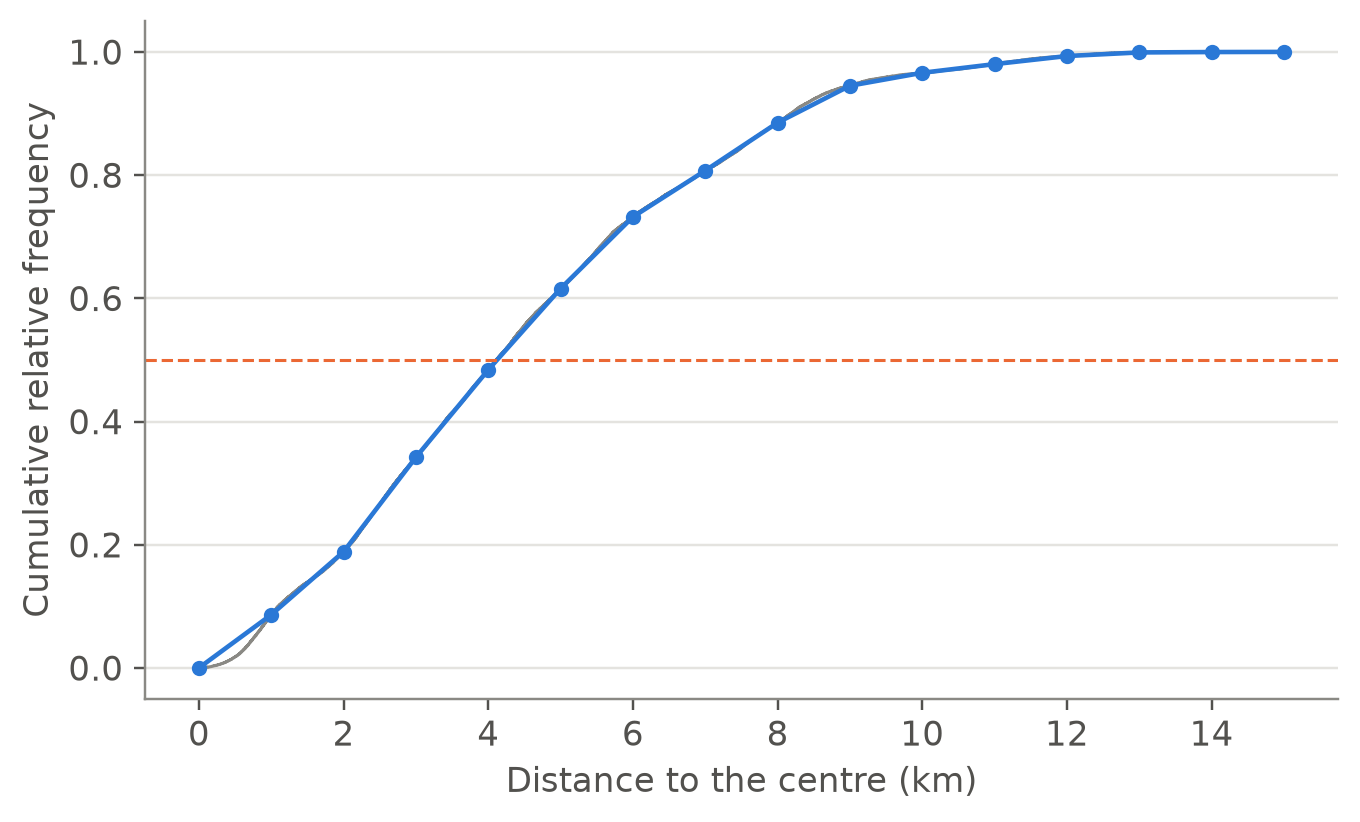

Median from the classes: 4.122 km   exact median: 4.114 km


In [11]:
#| label: fig-ogive
#| fig-cap: "Ogive of the distance to the centre in classes of 1 km (points and segments) over the empirical distribution function (thin line)."
p = 0.5
row = dist_table.with_columns(F_prev=pl.col("F_i").shift(1, fill_value=0.0)) \
    .filter(pl.col("F_i") >= p).row(0, named=True)
median_grouped = row["lower"] + (p - row["F_prev"]) / row["f_i"] * 1.0

x_sorted = np.sort(listings["dist_centre_km"].to_numpy())
fig, ax = plt.subplots()
ax.step(x_sorted, np.arange(1, len(x_sorted) + 1) / len(x_sorted), where="post",
        color=COLORS["grey"], linewidth=1)
ax.plot(np.r_[0, dist_table["lower"] + 1], np.r_[0, dist_table["F_i"]], "o-",
        color=COLORS["blue"], markersize=4)
ax.axhline(p, color=COLORS["orange"], ls="--", linewidth=1)
ax.set_xlabel("Distance to the centre (km)")
ax.set_ylabel("Cumulative relative frequency")
plt.show()
print(f"Median from the classes: {median_grouped:.3f} km   "
      f"exact median: {listings['dist_centre_km'].median():.3f} km")

### The geometric mean

For positive data, the **geometric mean** is
$$
G = \Big(\prod_{i=1}^n x_i\Big)^{1/n} = \exp\Big(\frac1n\sum_{i=1}^n \log x_i\Big),
$$
the mean computed on the logarithmic scale and brought back. It is the right mean for
quantities that combine by **multiplication**, such as growth rates
over time.

::: {#prp-am-gm}
## Inequality of the arithmetic and geometric means
For positive data, $G \le \bar x$, with equality if and only if all the $x_i$ are equal.
:::

::: {.proof}
We use the inequality $\log t \le t - 1$ for $t > 0$, with equality only at $t = 1$ (the
line $t - 1$ is tangent to the concave function $\log t$ at $t = 1$). With $t = x_i / \bar x$,
$$
\frac1n\sum_i \log\frac{x_i}{\bar x} \le \frac1n\sum_i\Big(\frac{x_i}{\bar x} - 1\Big) = 0,
$$
so $\log G - \log \bar x \le 0$. Equality requires $x_i / \bar x = 1$ for every $i$.
:::

In [12]:
listings.select(
    arithmetic=pl.col("price").mean(),
    geometric=pl.col("price").log().mean().exp(),
    median=pl.col("price").median(),
)

arithmetic,geometric,median
"388,892.1","280,307.5","257,000.0"


For right-skewed data such as prices, the geometric mean is much closer to the median
than the arithmetic mean is.

::: {.callout-note}
## Historical note: the median

In 1774 Pierre-Simon Laplace showed that, to combine several discordant
observations, the value that minimises the expected absolute error is the median of
their distribution, the probabilistic version of @prp-median. The idea remained
marginal for a century, while astronomers and geodesists used the mean, which
minimises squared errors and is easier to compute. It was Francis Galton who
popularised the median, and the English word, in the 1880s, as a summary of skewed data that
was easy to obtain by simply ranking the observations.
:::

## References {.unnumbered}

::: {#refs}
:::